# Pendahuluan

Di dalam material ini, kamu akan mempelajari Data Heart Disease dan belajar bagaimana melakukan pemodelan. Lakukan kode dan jalankan setiap sel. Selama proses pembelajaran, kamu akan menemui beberapa blok **TODO** -- ikuti petunjuk untuk mengisinya sebelum menjalankan sel-sel tersebut dan melanjutkan.

In [68]:
# Tahapan sebelumnya
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

data = "data.csv"
df = pd.read_csv(data, index_col=0)

df = df.drop(columns=['education'])
df['sex'] = df['sex'].replace({'Male': 1, 'Female': 0})
df['income'] = df['income'].replace({'<=50K': 0, '>50K': 1})

mappings = {}
for col in ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'native.country']:
    mappings[col] = {val: i for i, val in enumerate(sorted(df[col].unique()))}
    df[col] = df[col].replace(mappings[col])

df = df.astype(int)

print(df.dtypes)

age               int64
workclass         int64
fnlwgt            int64
education.num     int64
marital.status    int64
occupation        int64
relationship      int64
race              int64
sex               int64
capital.gain      int64
capital.loss      int64
hours.per.week    int64
native.country    int64
income            int64
dtype: object


In [69]:
df = df[['education.num', 'age', 'hours.per.week', 'capital.gain', 'sex', 'relationship', 'income']]
print(df.columns.tolist())

['education.num', 'age', 'hours.per.week', 'capital.gain', 'sex', 'relationship', 'income']


In [70]:
print(df.head())
print(df.columns)

   education.num  age  hours.per.week  capital.gain  sex  relationship  income
0              9   90              40             0    0             1       0
1              9   82              18             0    0             1       0
2             10   66              40             0    0             4       0
3              4   54              40             0    0             4       0
4             10   41              40             0    0             3       0
Index(['education.num', 'age', 'hours.per.week', 'capital.gain', 'sex',
       'relationship', 'income'],
      dtype='str')


**Memisahkan variabel dependen dan independen**

Variabel dependen yang digunakan adalah data pada kolom 'target', kolom feature merupakan variabel independen. Disini kamu akan membuat variabel X menggunakan .isin() untuk semua kolom kecuali kolom target, kemudian variabel y yang hanya kolom target saja.

In [71]:
X = df.loc[:, ~df.columns.isin(['income'])]
y = df['income']

In [72]:
# Melihat kolom yang termasuk variable indepnden
X.head()

,education.num,age,hours.per.week,capital.gain,sex,relationship
0,9,90,40,0,0,1
1,9,82,18,0,0,1
2,10,66,40,0,0,4
3,4,54,40,0,0,4
4,10,41,40,0,0,3


In [73]:
# Melihat variabel dependen
y.head()

0    0
1    0
2    0
3    0
4    0
Name: income, dtype: int64

In [74]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

**Spliting data**

Pisahkan dataset menjadi training dan testing dataset dengan perbandingan 80:20 dan random state 42!

In [75]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(26029, 6)
(6508, 6)
(26029,)
(6508,)


In [76]:
print(X_train.shape)

(26029, 6)


**Pemodelan dengan Heart Disease Dataset**

Kita akan melakukan pemodelan untuk 4 model berbeda diantaranya logistic regression, decision tree, random forest dan neural networks.

In [77]:
# Menyiapkan libraries
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [78]:
# Logistic Regression
clf = LogisticRegression(max_iter=500, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("The test accuracy score of Logistric Regression Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Logistric Regression Classifier is  0.8242163491087892


In [79]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4940
           1       0.73      0.44      0.54      1568

    accuracy                           0.82      6508
   macro avg       0.78      0.69      0.72      6508
weighted avg       0.81      0.82      0.81      6508



In [80]:
# Decision Tree
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("The test accuracy score of Decision Tree Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Decision Tree Classifier is  0.8157652120467117


In [81]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      4940
           1       0.64      0.55      0.59      1568

    accuracy                           0.82      6508
   macro avg       0.75      0.72      0.73      6508
weighted avg       0.81      0.82      0.81      6508



In [82]:
# Random Forest
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("The test accuracy score of Random Forest Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Random Forest Classifier is  0.8251382913337431


In [83]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.90      0.89      4940
           1       0.65      0.58      0.62      1568

    accuracy                           0.83      6508
   macro avg       0.76      0.74      0.75      6508
weighted avg       0.82      0.83      0.82      6508



In [84]:
# MLP
clf = MLPClassifier(max_iter=500, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("The test accuracy score of MLP Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of MLP Classifier is  0.844499078057775


In [85]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      4940
           1       0.73      0.57      0.64      1568

    accuracy                           0.84      6508
   macro avg       0.80      0.75      0.77      6508
weighted avg       0.84      0.84      0.84      6508



**Membandingkan hasil di atas**

Karena data target tidak seimbang (76% `<=50K` dan 24% `>50K`), model yang selalu menebak `<=50K` sudah mencapai akurasi sekitar 75,9%. Oleh karena itu, perbandingan model tidak hanya melihat akurasi, tetapi juga recall dan F1-score pada kelas `>50K`.

Berdasarkan hasil keempat model dengan 6 fitur terpilih (sebelum hyperparameter tuning):
- MLP memiliki performa terbaik: akurasi 84,4%, precision 0,73, recall 0,57, dan F1-score 0,64 pada kelas `>50K`.
- Random Forest memiliki recall kelas `>50K` tertinggi (0,58) dan F1-score 0,62, dengan akurasi 82,5%.
- Decision Tree memiliki akurasi 81,6% dan F1-score kelas `>50K` 0,59.
- Logistic Regression memiliki akurasi 82,4%, tetapi recall kelas `>50K` hanya 0,44, sehingga banyak responden berpenghasilan >50K yang tidak terdeteksi.

**Pojok Catatan**

Recall: Kemampuan model untuk menemukan semua kasus relevan dimana kebanyakan penting untuk deteksi risiko tinggi (seperti deteksi kanker), recall adalah metrik evaluasi yang lebih penting daripada presisi.

Dalam kasus prediksi gagal jantung, kita ingin menghindari false negatives sebanyak mungkin. Kasus false negative berarti masalah gagal jantung tidak terdeteksi, yang bisa sangat berbahaya. Dalam kasus penggunaan ini, false positives (seseorang yang sehat dengan diagnosis masalah jantung tidak sehat) tidak sepenting mencegah situasi ketika kita tidak mendeteksi masalah serius.

**Proses Hyperparameter Tuning**

In [86]:
# Logistic Regression
clf = LogisticRegression(random_state=42)

param_grid = {
    'max_iter': [100, 500, 1000],
    'solver': ['lbfgs', 'liblinear', 'saga']
}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_lg = gs1.fit(X_train, y_train)

print(fit_clf_lg.best_params_)
print(fit_clf_lg.best_score_)

{'max_iter': 100, 'solver': 'liblinear'}
0.8422078683390769


In [87]:
y_pred = fit_clf_lg.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4940
           1       0.73      0.44      0.54      1568

    accuracy                           0.82      6508
   macro avg       0.78      0.69      0.72      6508
weighted avg       0.81      0.82      0.81      6508



In [88]:
# Random Forest
clf = RandomForestClassifier(random_state=42)

param_grid = {'n_estimators': [100, 200, 300],
              'max_depth': [5, 10, 15],
              'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_rf = gs1.fit(X_train, y_train)

print(fit_clf_rf.best_params_)
print(fit_clf_rf.best_score_)

{'criterion': 'gini', 'max_depth': 10, 'n_estimators': 300}
0.9088495371673035


In [89]:
y_pred = fit_clf_rf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.95      0.91      4940
           1       0.77      0.54      0.64      1568

    accuracy                           0.85      6508
   macro avg       0.82      0.75      0.77      6508
weighted avg       0.84      0.85      0.84      6508



In [90]:
# Decision Tree
clf = DecisionTreeClassifier(random_state=42)

param_grid = {'min_samples_leaf': [1, 5, 10, 20],
              'max_depth': [3, 5, 7, 10],
              'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_dt = gs1.fit(X_train, y_train)

print(fit_clf_dt.best_params_)
print(fit_clf_dt.best_score_)

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 20}
0.9007083425534695


In [91]:
y_pred = fit_clf_dt.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.96      0.90      4940
           1       0.79      0.50      0.61      1568

    accuracy                           0.85      6508
   macro avg       0.82      0.73      0.76      6508
weighted avg       0.84      0.85      0.83      6508



In [92]:
# MLP
clf = MLPClassifier(max_iter=500, random_state=42)

param_grid1 = {'hidden_layer_sizes': [(50,), (100,), (50, 50)],
               'activation': ['relu', 'tanh'],
               'solver': ['adam', 'sgd']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid1,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_mlp = gs1.fit(X_train, y_train)

print(fit_clf_mlp.best_params_)
print(fit_clf_mlp.best_score_)

{'activation': 'relu', 'hidden_layer_sizes': (100,), 'solver': 'adam'}
0.9058925652631322


In [93]:
y_pred = fit_clf_mlp.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      4940
           1       0.73      0.57      0.64      1568

    accuracy                           0.84      6508
   macro avg       0.80      0.75      0.77      6508
weighted avg       0.84      0.84      0.84      6508



**Perbandingan hasil setelah hyperparameter tuning**

- Logistic Regression: parameter terbaik (max_iter=100, solver=liblinear) menghasilkan performa yang sama dengan sebelum tuning (akurasi 82%, recall kelas `>50K` 0,44, F1-score 0,54).
- Decision Tree: akurasi naik dari 81,6% menjadi 85% dan F1-score kelas `>50K` naik dari 0,59 menjadi 0,61. Kenaikan berasal dari precision (0,64 menjadi 0,79), sedangkan recall turun (0,55 menjadi 0,50). Pembatasan kedalaman pohon (max_depth=7) dan jumlah minimum sampel per daun (min_samples_leaf=20) membuat pohon lebih sederhana.
- Random Forest: akurasi naik dari 82,5% menjadi 85% dan F1-score kelas `>50K` naik dari 0,62 menjadi 0,64. Precision naik (0,65 menjadi 0,77), recall turun (0,58 menjadi 0,54). Model ini memiliki AUC validasi silang tertinggi (0,909).
- MLP: performa relatif tidak berubah (akurasi 84%, recall kelas `>50K` 0,57, F1-score 0,64).

Setelah tuning, recall kelas `>50K` turun pada Decision Tree dan Random Forest sementara precision naik. Pada threshold bawaan 0,5 model menjadi lebih berhati-hati memprediksi kelas `>50K`, sehingga analisis ROC dan pemilihan threshold dilakukan pada tahap berikutnya.

**ROC Analysis**

Kurva yang menyajikan ilustrasi performansi dari binary classifier system dalam menghasilkan sebuah prediksi

In [94]:
y_pred_logreg = fit_clf_lg.predict_proba(X_test)[:, 1]
y_pred_rf = fit_clf_rf.predict_proba(X_test)[:, 1]
y_pred_dt = fit_clf_dt.predict_proba(X_test)[:, 1]
y_pred_mlp = fit_clf_mlp.predict_proba(X_test)[:, 1]

auc_logreg = roc_auc_score(y_test, y_pred_logreg)
auc_rf = roc_auc_score(y_test, y_pred_rf)
auc_dt = roc_auc_score(y_test, y_pred_dt)
auc_mlp = roc_auc_score(y_test, y_pred_mlp)

print(f"AUC-ROC for Logistic Regression: {auc_logreg}")
print(f"AUC-ROC for Random Forest: {auc_rf}")
print(f"AUC-ROC for Decision Tree: {auc_dt}")
print(f"AUC-ROC for MLP: {auc_mlp}")

AUC-ROC for Logistic Regression: 0.8372335371395521
AUC-ROC for Random Forest: 0.9029020439147317
AUC-ROC for Decision Tree: 0.8916008685863009
AUC-ROC for MLP: 0.8969383236594233


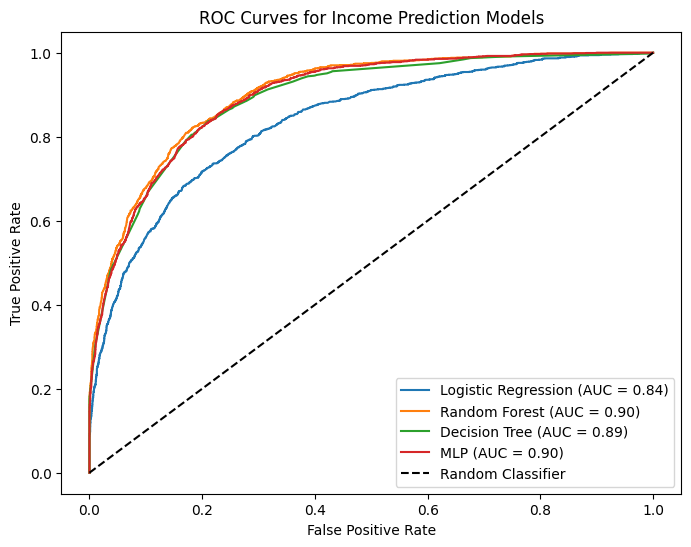

In [95]:
def plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp):
    plt.figure(figsize=(8, 6))

    fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_pred_logreg)
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
    fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
    fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_pred_mlp)

    plt.plot(fpr_logreg, tpr_logreg, label=f'Logistic Regression (AUC = {auc_logreg:.2f})')
    plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
    plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})')
    plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {auc_mlp:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Income Prediction Models')
    plt.legend()
    plt.show()

plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp)

In [96]:
def find_rates_for_thresholds(y_test, y_pred, thresholds):
    fpr_list = []
    tpr_list = []
    for threshold in thresholds:
        y_pred_binary = (y_pred > threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_binary).ravel()
        fpr = fp / (fp + tn)
        tpr = tp / (tp + fn)
        fpr_list.append(fpr)
        tpr_list.append(tpr)
    return fpr_list, tpr_list

thresholds = np.arange(0, 1.1, 0.1)

fpr_logreg, tpr_logreg = find_rates_for_thresholds(y_test, y_pred_logreg, thresholds)
fpr_rf, tpr_rf = find_rates_for_thresholds(y_test, y_pred_rf, thresholds)
fpr_dt, tpr_dt = find_rates_for_thresholds(y_test, y_pred_dt, thresholds)
fpr_mlp, tpr_mlp = find_rates_for_thresholds(y_test, y_pred_mlp, thresholds)

summary_df = pd.DataFrame({
    'Threshold': thresholds,
    'FPR_LogReg': fpr_logreg, 'TPR_LogReg': tpr_logreg,
    'FPR_RF': fpr_rf, 'TPR_RF': tpr_rf,
    'FPR_DT': fpr_dt, 'TPR_DT': tpr_dt,
    'FPR_MLP': fpr_mlp, 'TPR_MLP': tpr_mlp
})

print(summary_df.round(3))

    Threshold  FPR_LogReg  TPR_LogReg  FPR_RF  TPR_RF  FPR_DT  TPR_DT  \
0         0.0       1.000       1.000   1.000   1.000   0.996   0.998   
1         0.1       0.543       0.920   0.375   0.955   0.361   0.931   
2         0.2       0.302       0.807   0.262   0.886   0.257   0.872   
3         0.3       0.167       0.682   0.186   0.824   0.188   0.811   
4         0.4       0.098       0.557   0.109   0.695   0.103   0.666   
5         0.5       0.052       0.436   0.051   0.542   0.042   0.496   
6         0.6       0.027       0.323   0.032   0.470   0.037   0.481   
7         0.7       0.012       0.225   0.014   0.360   0.011   0.307   
8         0.8       0.005       0.162   0.003   0.217   0.001   0.184   
9         0.9       0.001       0.110   0.000   0.168   0.000   0.168   
10        1.0       0.000       0.000   0.000   0.000   0.000   0.000   

    FPR_MLP  TPR_MLP  
0     1.000    1.000  
1     0.357    0.939  
2     0.249    0.870  
3     0.182    0.800  
4     0.

In [97]:
def find_best_threshold(y_test, y_pred):
    # based on Youden's Index
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    optimal_idx = np.argmax(tpr - fpr)
    return thresholds[optimal_idx]

best_threshold_logreg = find_best_threshold(y_test, y_pred_logreg)
best_threshold_rf = find_best_threshold(y_test, y_pred_rf)
best_threshold_dt = find_best_threshold(y_test, y_pred_dt)
best_threshold_mlp = find_best_threshold(y_test, y_pred_mlp)

print(f"Best threshold for Logistic Regression: {best_threshold_logreg}")
print(f"Best threshold for Random Forest: {best_threshold_rf}")
print(f"Best threshold for Decision Tree: {best_threshold_dt}")
print(f"Best threshold for MLP: {best_threshold_mlp}")

Best threshold for Logistic Regression: 0.27009368043284077
Best threshold for Random Forest: 0.3043415776647347
Best threshold for Decision Tree: 0.2796208530805687
Best threshold for MLP: 0.2232592244232702


**Ingat**

1. Jika menginginkan sensitivitas (recall) yang tinggi, yaitu mendeteksi sebanyak mungkin kasus positif, gunakan threshold yang lebih rendah. Konsekuensinya False Positive Rate (FPR) ikut naik.
2. Sebaliknya, threshold yang lebih tinggi mengurangi kesalahan memprediksi kasus negatif sebagai positif, tetapi menurunkan sensitivitas.

Berdasarkan hasil di atas, model **Random Forest** dipilih sebagai model terbaik karena:
- Memiliki nilai AUC-ROC tertinggi (0,903), dibandingkan MLP (0,897), Decision Tree (0,892), dan Logistic Regression (0,837).
- Pada threshold terbaik (0,304), Random Forest mencapai recall 0,82, precision 0,59, F1-score 0,69, dan akurasi 82% pada kelas `>50K`. MLP pada threshold terbaiknya (0,223) memiliki recall lebih tinggi (0,86), tetapi precision (0,54), F1-score (0,66), dan akurasi (79%) lebih rendah.
- Selisih recall MLP hanya 53 responden `>50K` lebih banyak terdeteksi, dengan tambahan 232 salah prediksi pada kelas `<=50K`.

Pada threshold bawaan 0,5, recall kelas `>50K` Random Forest hanya 0,54. Dengan menurunkan threshold menjadi 0,304, recall naik menjadi 0,82 dengan konsekuensi precision turun dan FPR naik menjadi 0,183. Karena itu model Random Forest digunakan dengan threshold 0,304.

In [98]:
for nama, prob, thr in [("Random Forest", y_pred_rf, best_threshold_rf),
                        ("MLP", y_pred_mlp, best_threshold_mlp)]:
    y_pred_best = (prob >= thr).astype(int)
    print("=====", nama, "| threshold:", round(thr, 3), "=====")
    print(confusion_matrix(y_test, y_pred_best))
    print(classification_report(y_test, y_pred_best))

===== Random Forest | threshold: 0.304 =====
[[4036  904]
 [ 279 1289]]
              precision    recall  f1-score   support

           0       0.94      0.82      0.87      4940
           1       0.59      0.82      0.69      1568

    accuracy                           0.82      6508
   macro avg       0.76      0.82      0.78      6508
weighted avg       0.85      0.82      0.83      6508

===== MLP | threshold: 0.223 =====
[[3804 1136]
 [ 226 1342]]
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4940
           1       0.54      0.86      0.66      1568

    accuracy                           0.79      6508
   macro avg       0.74      0.81      0.76      6508
weighted avg       0.85      0.79      0.80      6508



In [99]:
import pickle

best_model = fit_clf_rf.best_estimator_

artifact = {
    'model': best_model,
    'scaler': scaler,
    'mappings': mappings,
    'features': list(X.columns),
    'threshold': float(best_threshold_rf)
}

pklname = 'generate_income.pkl'

with open(pklname, 'wb') as file:
    pickle.dump(artifact, file)

print("Tersimpan:", pklname, "| fitur:", artifact['features'])

Tersimpan: generate_income.pkl | fitur: ['education.num', 'age', 'hours.per.week', 'capital.gain', 'sex', 'relationship']
